<h1><center>Data Analysis and Simulation</center></h1>
<h3><center>Working notebook</center></h3>

# Imports

In [1]:
# Matplotlib setup, could be swapped for pyqt (realtime) or data shader(large datasets)
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
%config InlineBackend.figure_format = 'retina'

# Dependencies
import astropy.constants as c
import astropy.units as u
from astropy.coordinates import EarthLocation, AltAz, SkyCoord
from astropy.time import Time
import glob
import numpy as np
import os
import h5py
from rich.progress import track
import scipy
from scipy import ndimage
from scipy.signal import medfilt
from scipy.signal import welch
from scipy.signal import csd
from scipy.signal.windows import blackmanharris
from scipy.spatial.distance import pdist

# Parameter Initilization 
Insert correct parameters for the interferometer here

When simulating; simulate_antennas = True

When using real data; simulate_antennas = False


In [2]:
# Define key interferometer parameters
#TODO should be all caps
central_freq = 1416.4*u.MHz
#TODO should this be renamed bandwidth?
n_channels = 2**11 
samp_rate = 10*u.MHz #a.k.a. bandwidth
dt = 1/samp_rate
SUBBANDS_OFFSET = 430 

# Define antenna positions in local coordinates (x, y, z) in meters
posx = [0.44351937, 0.31049445, 0.49270715, -0.40862047, -0.00241969, -0.33720132, 0.08623691, -0.21437422, -0.37034218]
posy = [0.25675033, -0.36953188, 0.00338735, 0.09358719, 0.52380058, 0.36831369, -0.3100637, -0.22048946, -0.34575411]
posz = [0, 0, 0, 0, 0, 0, 0, 0, 0]
num_antennas = len(posx)

# Observation coordinates and time(s)
lat = 52.167*u.deg
lon = 4.461*u.deg
height = 1*u.m
leiden = EarthLocation(lat=lat, lon=lon, height=height)
obs_times = [Time('2026-11-20 21:00:00')]

# pointing direction
az = 0.1 * u.deg
alt = 90 * u.deg #zenith

# Integration parameters
int_time = 30 * u.min

# Algo control params
#TODO Should be all caps
simulate_antennas = True # toggle artificial antennas generation here
FOLDER_NOMENCLATURE = 'data_*'
FILE_NOMENCLATURE = 'init_data_*'


# 1.  Antenna Config 

In [3]:
# assemble position array and derive important properties
pos = np.array([posx, posy, posz]).T*u.m
%store pos
largest_baseline = np.max(pdist(pos)) * u.m
%store largest_baseline
print(f"Array comprised of {num_antennas} antennas with a largest baseline of {largest_baseline:.2f} and data from {len(obs_times)} distinct times")

Stored 'pos' (Quantity)
Stored 'largest_baseline' (Quantity)
Array comprised of 9 antennas with a largest baseline of 1.01 m and data from 1 distinct times


### 1.1 compute UV plane

In [4]:
def compute_uv_coordinates(ant_pos, hour_angles, dec, dtype=np.float32):
  num_ant = len(ant_pos)
  num_times = len(hour_angles)

  dec_rad = np.radians(dec)
  hour_angles_rad = np.radians(hour_angles)

  east = ant_pos[:, 0]
  north = ant_pos[:, 1]
  el = ant_pos[:, 2]

  dx = east[np.newaxis, :] - east[:, np.newaxis]
  dy = north[np.newaxis, :] - north[:, np.newaxis]
  dz = el[np.newaxis, :] - el[:, np.newaxis]

  result = np.zeros((num_times, num_ant, num_ant, 3), dtype=dtype)

  for t_idx, h in enumerate(hour_angles_rad):
    sin_h = np.sin(h)
    cos_h = np.cos(h)
    sin_dec = np.sin(dec_rad)
    cos_dec = np.cos(dec_rad)

    u = sin_h*dx + cos_h*dy
    v = -sin_dec*cos_h*dx + sin_dec*sin_h*dy + cos_dec*dz
    w = cos_dec*cos_h*dx - cos_dec*sin_h*dy + sin_dec*dz

    result[t_idx, :, :, 0] = u
    result[t_idx, :, :, 1] = v
    result[t_idx, :, :, 2] = w

  idx = np.arange(num_ant)
  #result[:, idx, idx, :] = np.nan

  return result

### 1.2 UV coverage of Earth rotation during integration time

In [5]:
#calculate the alt az, galactic and ra dec coordinates of leiden at the observation times
altaz_frames = [AltAz(obstime=obs_times[i], location=leiden) for i in range(len(obs_times))]
altaz_coords = [SkyCoord(alt=alt, az=az, frame=altaz_frames[i]) for i in range(len(altaz_frames))]
galactic_coords = [coord.transform_to('galactic') for coord in altaz_coords]
radec_coords = [coord.transform_to('icrs') for coord in altaz_coords]

integration_hour_angles = np.linspace(0, int_time.to_value(u.h), 30)*15*u.deg

# UV coverage
uv = compute_uv_coordinates(pos, integration_hour_angles, alt) * u.m
%store uv
uvwl = (uv * central_freq / c.c).decompose()
u_coords = uvwl[:, :, :, 0].value
v_coords = uvwl[:, :, :, 1].value


Stored 'uv' (Quantity)


### 1.3 Visualize antenna configuration

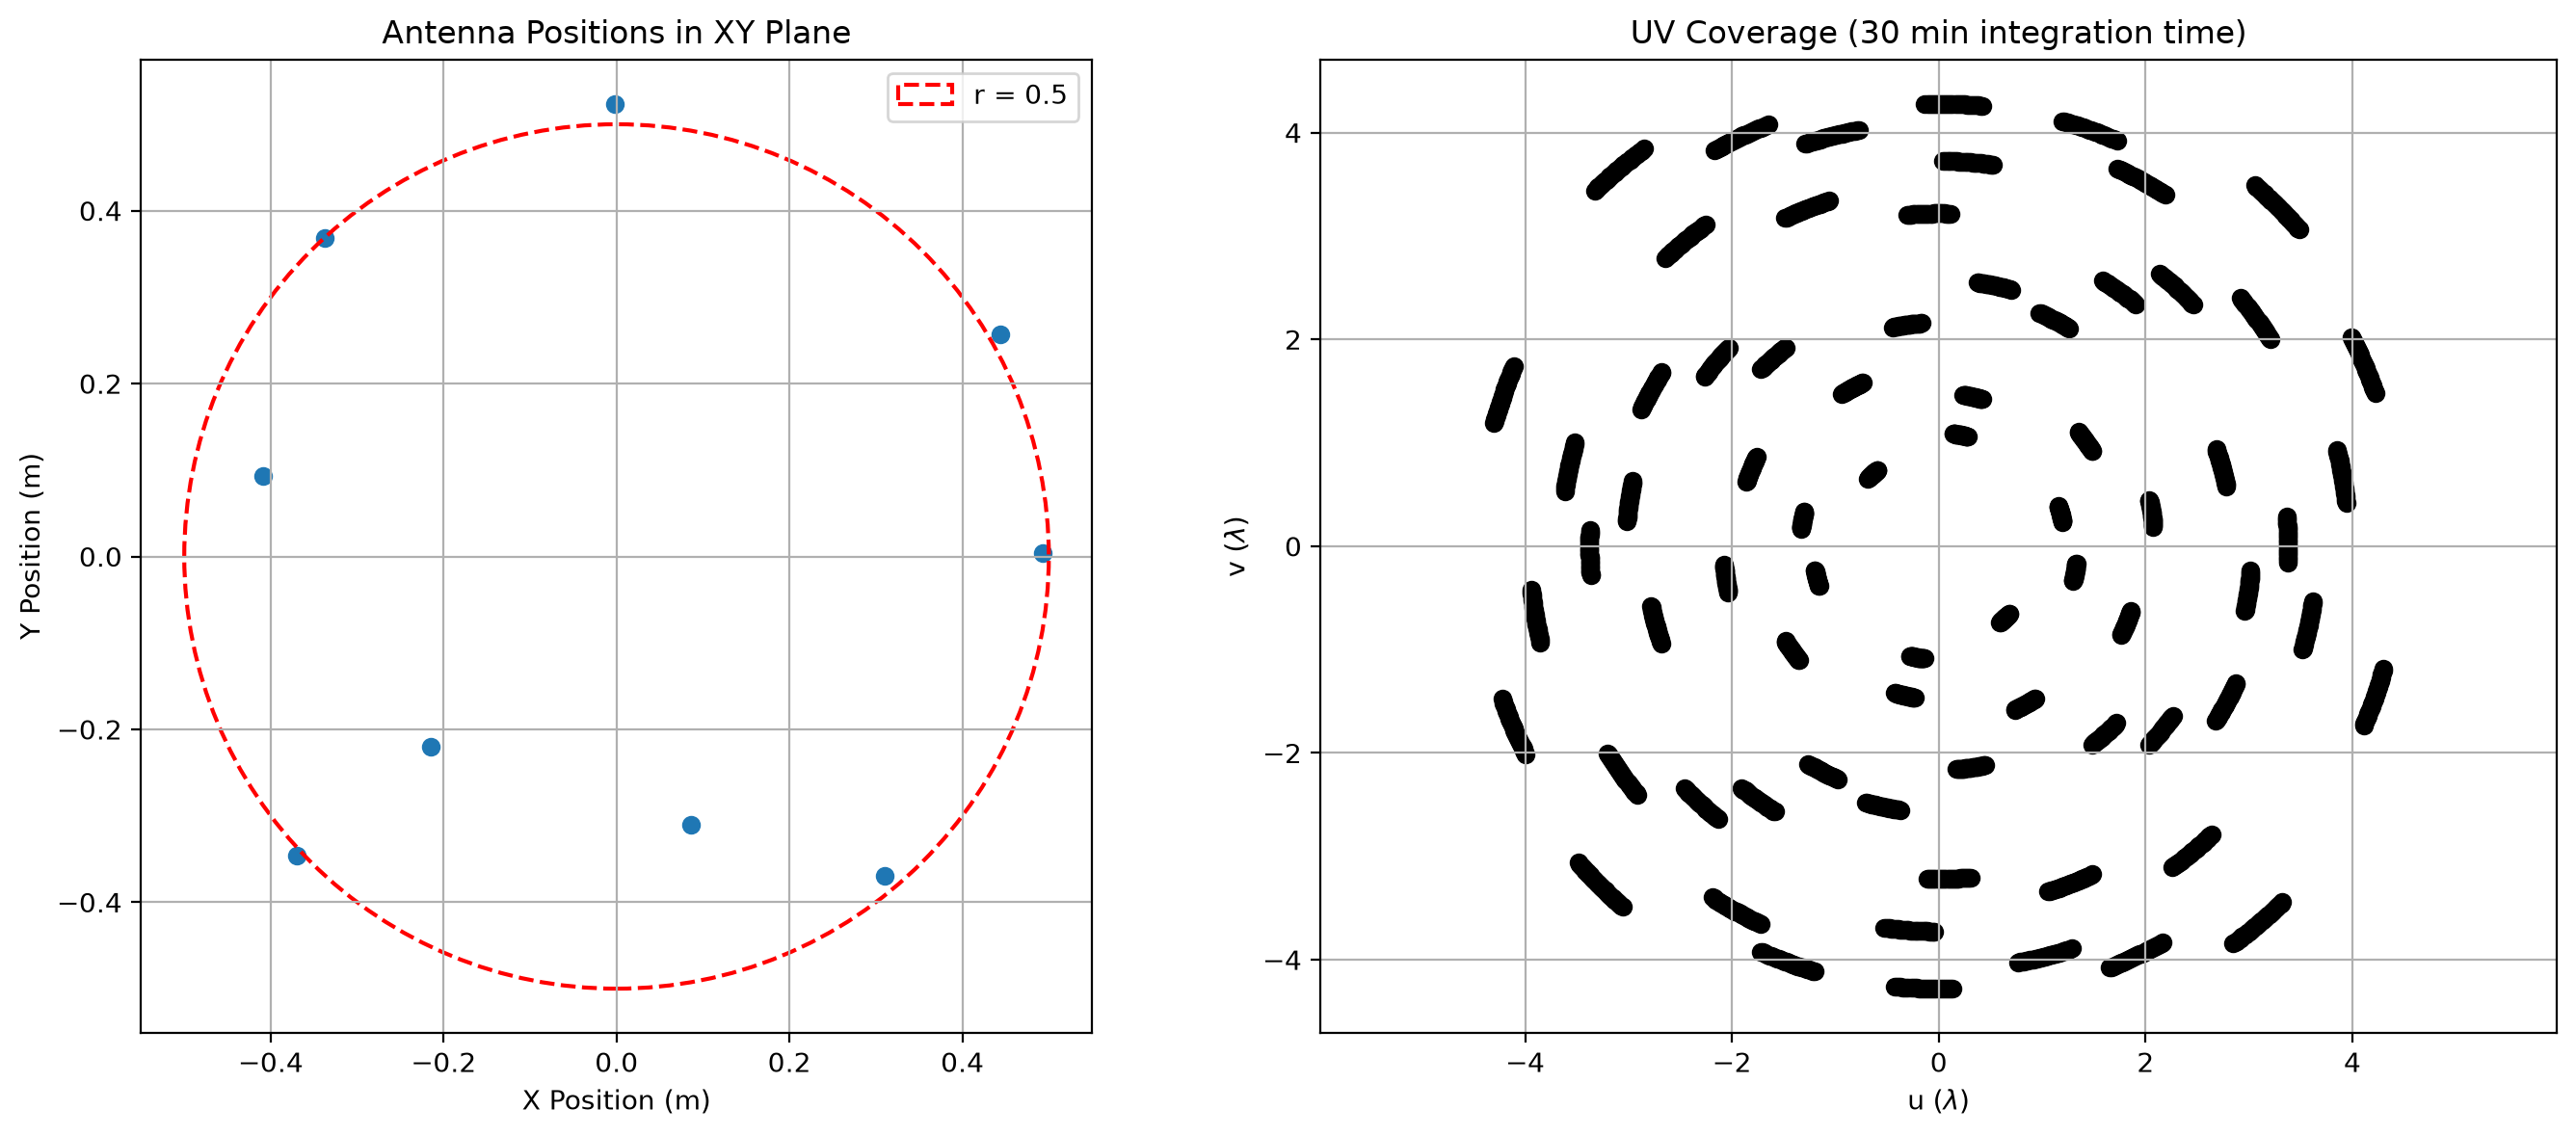

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Antenna configuration
ax[0].scatter(pos[:, 0].value, pos[:, 1].value)

ax[0].set_xlabel('X Position (m)')
ax[0].set_ylabel('Y Position (m)')
ax[0].set_title('Antenna Positions in XY Plane')
ax[0].grid()
ax[0].set_aspect('equal')

# Add red circle centered at (0,0), radius = 0.5 m
circle = Circle((0, 0), radius=0.5, edgecolor='red', facecolor='none', linewidth=1.5, linestyle='dashed', label = 'r = 0.5')
ax[0].add_patch(circle)
ax[0].legend()

# Plot individual baseline tracks
for i in range(num_antennas):
    for j in range(num_antennas):
        if i != j:
            ax[1].scatter(u_coords[:, i, j],v_coords[:, i, j],color='black')

ax[1].set_xlabel(r'u ($\lambda$)')
ax[1].set_ylabel(r'v ($\lambda$)')
ax[1].set_title(f'UV Coverage ({int_time.to_value(u.min):.0f} min integration time)')
ax[1].grid()
ax[1].axis('equal')
plt.tight_layout()
plt.show()

# 2. Load the data

Set the folder

In [7]:
CWD = os.getcwd()
OBS_FOLDER = os.path.join(CWD, 'observations')

files = glob.glob(os.path.join(OBS_FOLDER, FOLDER_NOMENCLATURE, FILE_NOMENCLATURE))
raw_data = [np.fromfile(file, dtype=np.complex64) for file in track(files, description="Loading data")]

Output()

### 2.1 Visualize raw data

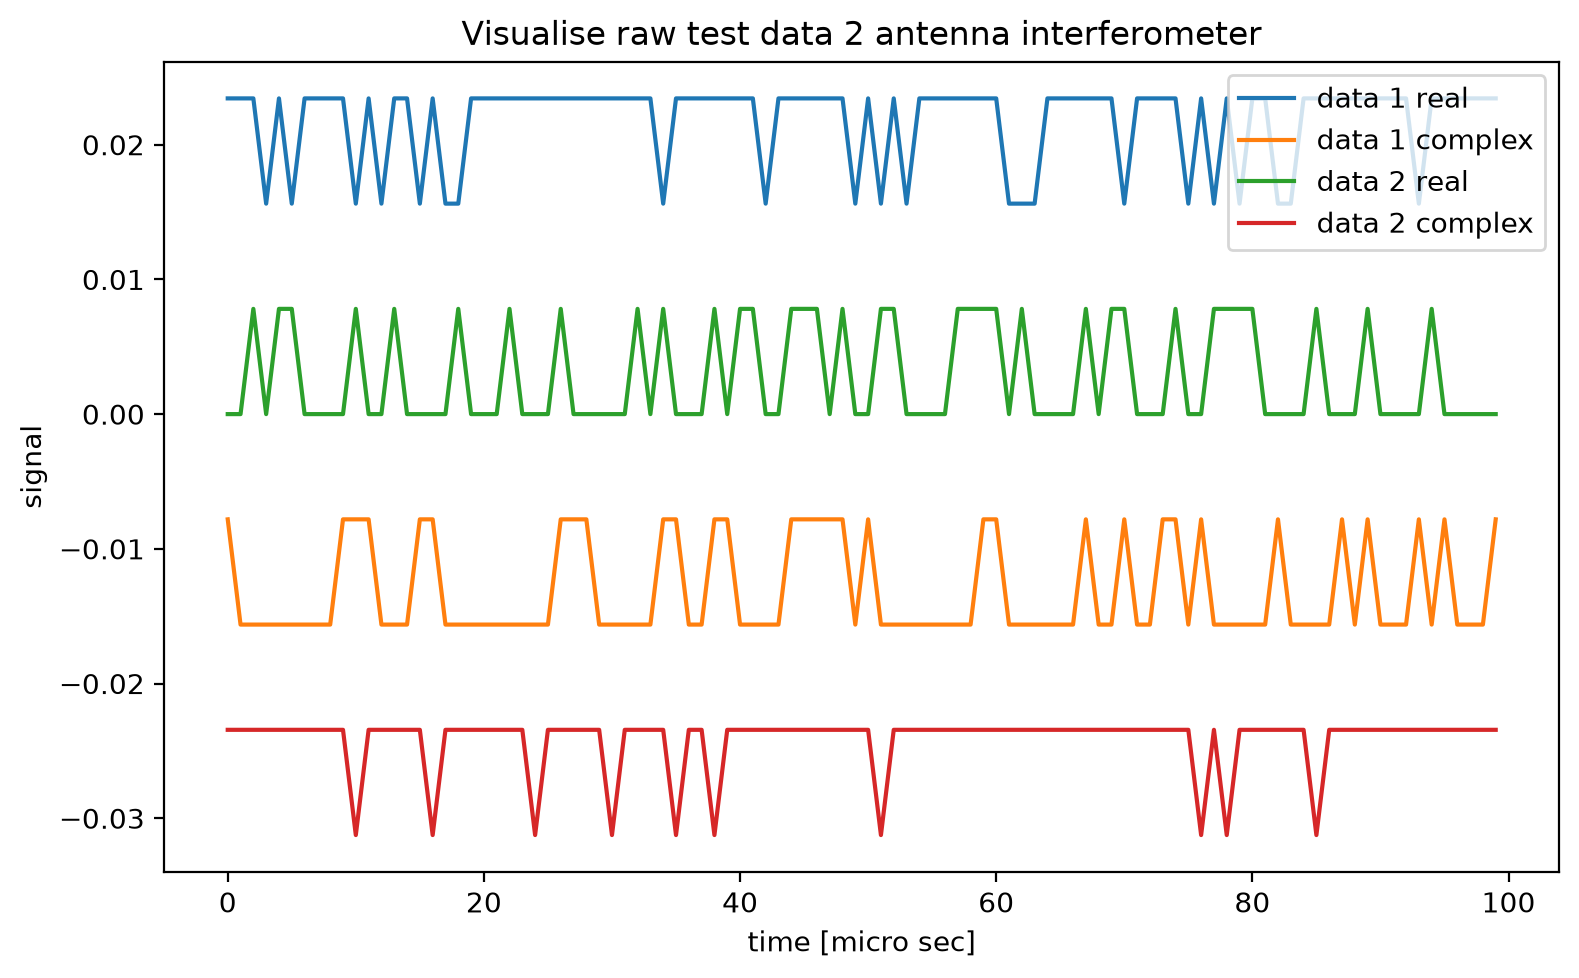

In [8]:
# visualise cut out of raw data
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Visualise raw test data 2 antenna interferometer')
ax.plot(np.real(raw_data[0][0:100]), label = 'data 1 real')
ax.plot(np.imag(raw_data[0][0:100]), label = 'data 1 complex')
ax.plot(np.real(raw_data[1][0:100]), label = 'data 2 real')
ax.plot(np.imag(raw_data[1][0:100]), label = 'data 2 complex')
ax.set_xlabel("time [micro sec]")
ax.set_ylabel('signal')
ax.legend()
fig.tight_layout()
plt.show()

### 2.2 Truncate the data to uniformity

All data must have the same length

In [9]:
# Number of real observations and antennas
n_real_ant = len(raw_data)
n_obs = len(obs_times)

# Sampling frequency in Hz
fs = samp_rate.to_value(u.Hz)

# Duration of one FFT block
t_fft = n_channels / fs * u.s

# Shortest recording (samples per antenna, across all observations)
minlen = min(len(data) for data in raw_data)

# Assume each antenna recording contains n_obs consecutive observations
# Divide the available samples equally between observations
samples_per_obs_available = minlen // n_obs

# Number of complete FFT blocks per observation
nblocks_per_int = samples_per_obs_available // n_channels   // 10   # division to reduce quantity of data so as to not max out memory

# Samples retained per observation
truncation_index = nblocks_per_int * n_channels

# Total samples retained per antenna
total_samples = n_obs * truncation_index

# Actual integration time per observation
int_time = nblocks_per_int * t_fft

# Truncate and reshape the recordings
truncated_data = np.array([data[:truncation_index] for data in raw_data])

# Shape: (observation, antenna, samples)
truncated_data = truncated_data.reshape(n_obs, n_real_ant, truncation_index)

# Allocate data array for real and artificial antennas
data_array = np.zeros((n_obs, num_antennas, truncation_index),dtype=np.result_type(truncated_data.dtype, np.complex64))

data_array[:, :n_real_ant, :] = truncated_data

print(f"Number of observations: {n_obs}")
print(f"Number of real antennas: {n_real_ant}")
print(f"FFT blocks per integration: {nblocks_per_int}")
print(f"Samples per integration: {truncation_index}")
print(f"Integration time: {int_time.to(u.min):.3f}")
print(f"Total recording time: {(n_obs * int_time).to(u.min):.3f}")
print(f"FFT block duration: {t_fft.to(u.ms):.3f}")

Number of observations: 1
Number of real antennas: 2
FFT blocks per integration: 7878
Samples per integration: 16134144
Integration time: 0.027 min
Total recording time: 0.027 min
FFT block duration: 0.205 ms


### 2.3 create uvwl block that tracks the earths rotation during integration

In [10]:
# Define fixed celestial source position
source_icrs = altaz_coords[0].transform_to('icrs')

# Midpoint of each FFT block
integration_offsets = ((np.arange(nblocks_per_int) + 0.5) * t_fft)

# Store UVW coordinates for every observation and FFT block
uv_blocks = np.zeros((n_obs, nblocks_per_int, num_antennas, num_antennas, 3),dtype=np.float32)

for i, obs_time in enumerate(obs_times):

    # Time of every FFT block
    block_times = obs_time + integration_offsets

    # Local sidereal time
    lst = block_times.sidereal_time('apparent',longitude=leiden.lon)

    # Hour angle of the fixed celestial source
    hour_angles_blocks = (lst - source_icrs.ra).wrap_at(180 * u.deg).to_value(u.deg)

    # Calculate UVW coordinates
    uv_blocks[i] = compute_uv_coordinates(pos,hour_angles_blocks,lat.to_value(u.deg))

uv_blocks *= u.m

# Convert to wavelengths to observing frequency
uvwl_blocks = (uv_blocks * central_freq / c.c).decompose()

### 2.4 simulate antenna's 

In [11]:
if simulate_antennas:
    # Frequency offsets of the FFT bins
    freq_offsets = np.fft.fftfreq(n_channels, d=1/fs)
    simfreqs = freq_offsets + central_freq.to_value(u.Hz)

    # Baselines from the reference antenna to every antenna (metres)
    baselines = (pos - pos[0]).to_value(u.m)

    # Process several FFT blocks together. This avoids doing an Astropy
    # coordinate transformation and an FFT separately for every antenna/block.
    chunk_size = 256
    n_artificial = num_antennas - n_real_ant

    if n_artificial > 0 and nblocks_per_int > 0:
        for i in range(n_obs):
            reference_blocks = data_array[i, 0, :].reshape(
                nblocks_per_int, n_channels
            )

            for first in track(
                range(0, nblocks_per_int, chunk_size),
                description=f"Simulating observation {i + 1}/{n_obs}"
            ):
                last = min(first + chunk_size, nblocks_per_int)

                # FFT all reference blocks in this chunk at once
                reference_fft = np.fft.fft(
                    reference_blocks[first:last], axis=-1
                )

                # Calculate the source direction once per block (not once
                # per artificial antenna).
                block_times = obs_times[i] + integration_offsets[first:last]
                source_altaz = source_icrs.transform_to(
                    AltAz(obstime=block_times, location=leiden)
                )

                az = source_altaz.az.to_value(u.rad)
                alt = source_altaz.alt.to_value(u.rad)

                # Incoming wave direction in local ENU coordinates
                s_enu = np.column_stack((
                    np.cos(alt) * np.sin(az),
                    np.cos(alt) * np.cos(az),
                    np.sin(alt)
                ))

                # One geometric delay per block and artificial antenna
                for k in range(n_real_ant, num_antennas):
                    tau = (
                        s_enu @ baselines[k]
                    ) / c.c.to_value(u.m / u.s)

                    # Apply the frequency-dependent geometric phase delay
                    phase_shift = np.exp(
                        -2j * np.pi * tau[:, np.newaxis] * simfreqs[np.newaxis, :]
                    )

                    shifted_blocks = np.fft.ifft(
                        reference_fft * phase_shift, axis=-1
                    )

                    data_array[i, k, first * n_channels:last * n_channels] = (
                        shifted_blocks.reshape(-1)
                    )

    print(
        f"Antenna simulation completed: {n_artificial} artificial antennas, "
        f"{n_obs} observations and {nblocks_per_int} FFT blocks per observation."
    )
else:
    print("Antenna simulation skipped (simulate_antennas=False).")


Output()

Antenna simulation completed: 7 artificial antennas, 1 observations and 7878 FFT blocks per observation.


### 2.5 Calculate FFT of the antennas

In [12]:
window = blackmanharris(n_channels)
freq = np.zeros(truncation_index)
fft_data = np.zeros((len(obs_times), num_antennas, n_channels), dtype='complex64')

# Calculate FFTs
for k in track(range(len(obs_times)), description='Iterating through observations'):
    for i in track(range(num_antennas), description="Computing FFTs for each antenna"):
        df = data_array[k, i, :]
        df = df - np.mean(df) # Remove DC offset 
        frequency, fft_output = welch(df, fs=samp_rate, window=window, nperseg=n_channels, return_onesided=False)
        freq = np.fft.fftshift(frequency) + central_freq.to(u.Hz)
        fft_data[k, i] = np.fft.fftshift(fft_output)


Output()

Computing FFTs for each antenna ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:09

### 2.6 Visualise the FFT's

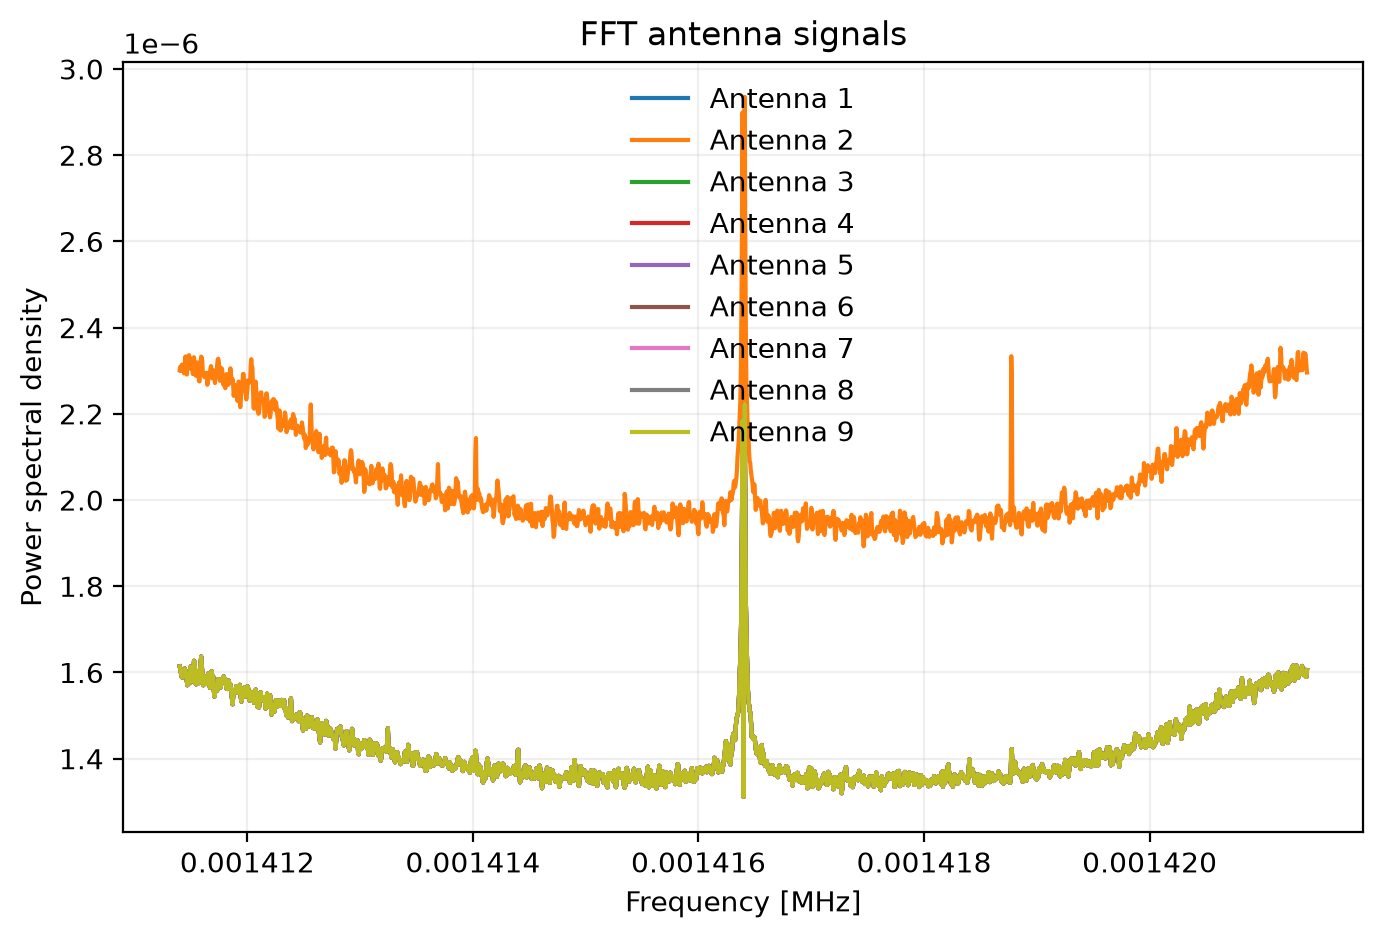

In [ ]:
# Plot FFT
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('FFT antenna signals')
for antenna in range(len(fft_data[0])):
    ax.plot(freq / 1e6, np.real(fft_data[0, antenna]), label=f'Antenna {antenna+1}')
ax.set_xlabel('Frequency [MHz]')
ax.set_ylabel('Power spectral density')
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 2.7 plot the shifted cross correlation to check for time delays

/tmp/ipykernel_101219/1716035707.py:19: ComplexWarning: Casting complex values to real discards the imaginary part
  correlations[i] = np.sum(cross_spectrum)


Maximum correlation: 5.9951563713411815e-09
Time delay: 0.0 seconds
Sample shift: 50


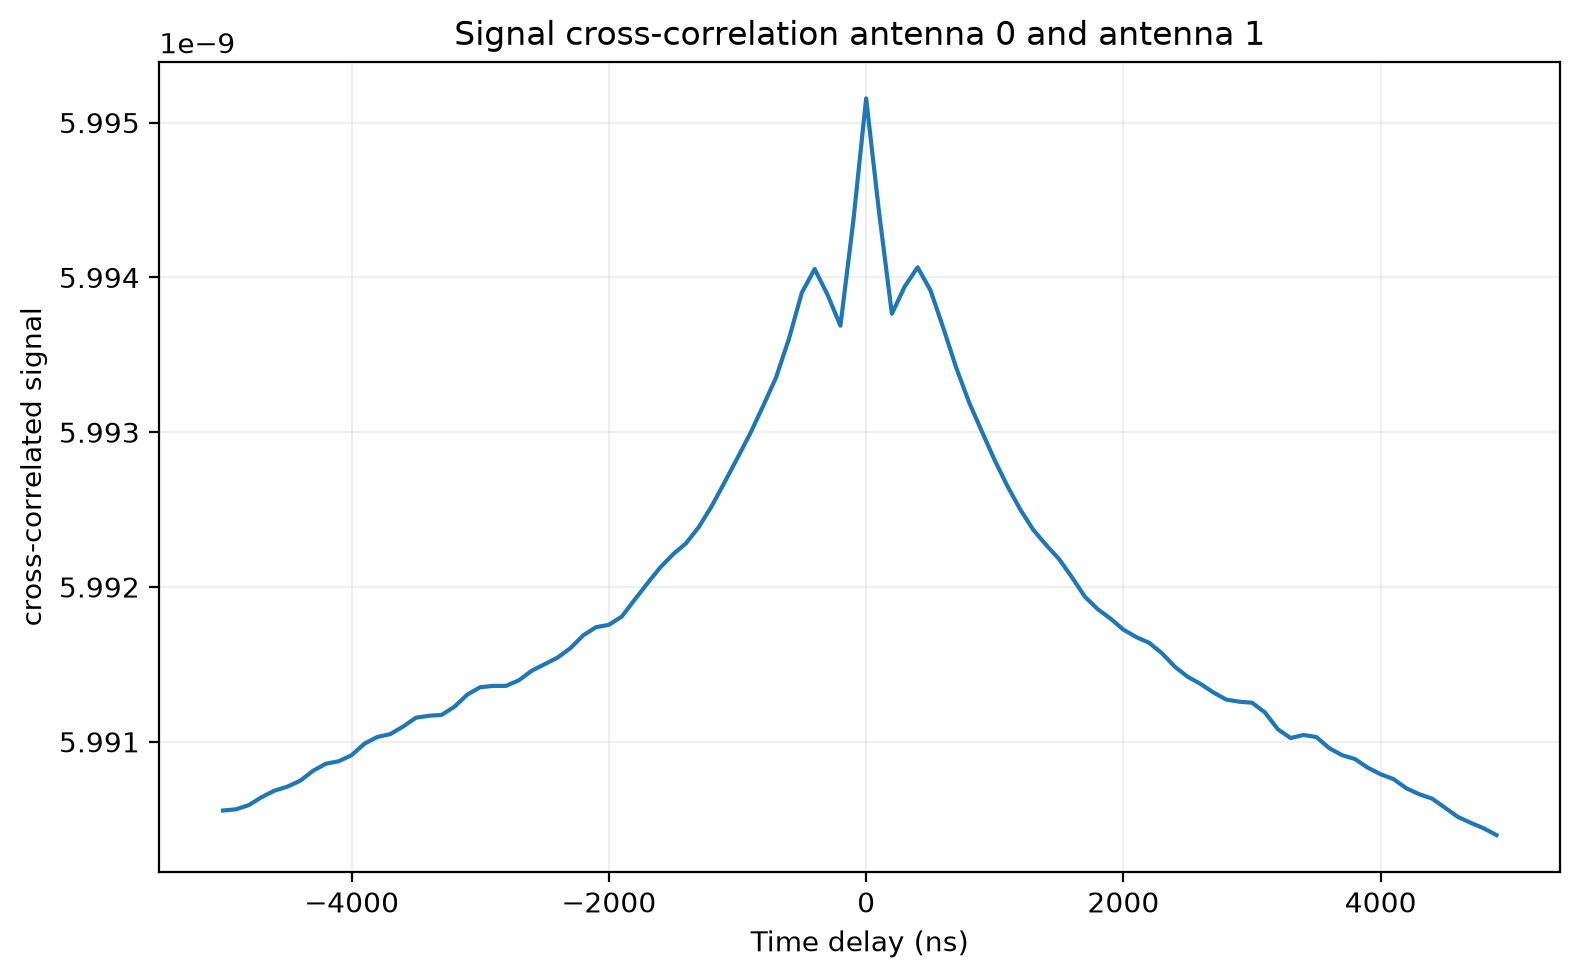

In [14]:
# correlate the signal of two antenna's of choice
ant1 = 0
ant2 = 1
n_shifts = 100

correlations = np.zeros(n_shifts)
time_delays = np.zeros(n_shifts)

for i in range(n_shifts):
    antenna2 = fft_data[0, ant2]
    
    # Shift antenna 2 from -50 to +50 datapoints
    shifted_a2 = np.roll(antenna2, i-50)

    # cross correlate the two spectra
    cross_spectrum = fft_data[0, ant1] * np.conj(shifted_a2)
    
    # Calculate correlation coefficient
    correlations[i] = np.sum(cross_spectrum)

    # Convert sample shift to time delay (dt per data point)
    time_delays[i] = i * dt.to(1/u.Hz).value - (50*dt.to(1/u.Hz).value)

# Find maximum correlation
max_index = np.argmax(np.abs(correlations))

print('Maximum correlation:', correlations[max_index])
print('Time delay:', time_delays[max_index], 'seconds')
print('Sample shift:', max_index)

# visualise time delayed cross correlation
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title(f'Signal cross-correlation antenna {ant1} and antenna {ant2}')
ax.plot(time_delays * 1e9, correlations)
ax.set_xlabel('Time delay (ns)')
ax.set_ylabel('cross-correlated signal')
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### 3 Compute ACM cube
calculate subband visibilities (cross-correlations) and add them to a data cube

In [15]:
subband = (n_channels // 2) + SUBBANDS_OFFSET # look at an offset of subbands after the center

acm = np.zeros((len(obs_times), num_antennas, num_antennas), dtype='complex64')
for i in track(range(len(obs_times)), description='Iterating through observations'):
  obs_data = data_array[i]
  for ant1 in track(range(num_antennas), description='Computing ACM for observation'):
    for ant2 in range(ant1, num_antennas):
      freq, cross_corr = csd(obs_data[ant1], obs_data[ant2], fs=samp_rate, nperseg=n_channels, return_onesided=False)
      acm[i, ant1, ant2] = cross_corr[subband]

      if ant1 != ant2:
        acm[i, ant2, ant1] = np.conj(cross_corr[subband]) # property of frequency domain cross-correlation, saves time

print('ACM generated successfully!')

Output()

Computing ACM for observation ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:01:30

ACM generated successfully!


### 3.1 Define make_image function + helper function

In [16]:
# Helper functions for generating images
def pixel_brightness(acm_single_pol, l, m, uv, frequency):
    a = acm_single_pol.astype(np.complex64)
    n = a.shape[0]
    uv_l = uv.astype(np.float32)
    uv_l = (uv_l * frequency/c.c).decompose()
    ll = l.to(u.rad).value
    mm = m.to(u.rad).value
    mask = np.ones((n, n), dtype=np.float32)
    mask -= np.diag(np.ones(n, dtype=np.float32)) # remove auto-correlations
    num_vis = mask.sum()
    brightness = (a*mask*np.exp(2j*np.pi*(uv_l[...,0]*ll + uv_l[...,1]*mm))).real.sum()
    return brightness/num_vis

def subband_frequency(subband_number, clock_frequency=samp_rate):
    return (subband_number/n_channels)*clock_frequency + (central_freq - clock_frequency/2)
    
def make_image(acm, num_pix, uv, frequency,
               l_range=(1.0, -1.0),
               m_range=(-1.0, 1.0)):

    img = np.zeros((num_pix, num_pix), dtype=np.float32)

    l_coor = np.linspace(*l_range, num_pix) * u.rad
    m_coor = np.linspace(*m_range, num_pix) * u.rad

    # Loop over image pixels
    for m_ix, m in enumerate(track(m_coor, description="Generating image")):

        for l_ix, l in enumerate(l_coor):

            # Calculate brightness for every FFT block
            brightness = 0

            for b in range(acm.shape[0]):

                brightness += pixel_brightness(acm[b], l, m, uv[b], frequency)

            # Average over the integration
            img[m_ix, l_ix] = brightness / acm.shape[0]

    pixel_sep = m_coor[1] - m_coor[0]
    half = pixel_sep.to_value(u.rad) / 2

    img_extent = (l_coor[0].value - half, l_coor[-1].value + half, m_coor[0].value - half, m_coor[-1].value + half)

    return img, img_extent

### 3.2 Make image of observation at chosen subband

Output()

Number of pixels should be 23


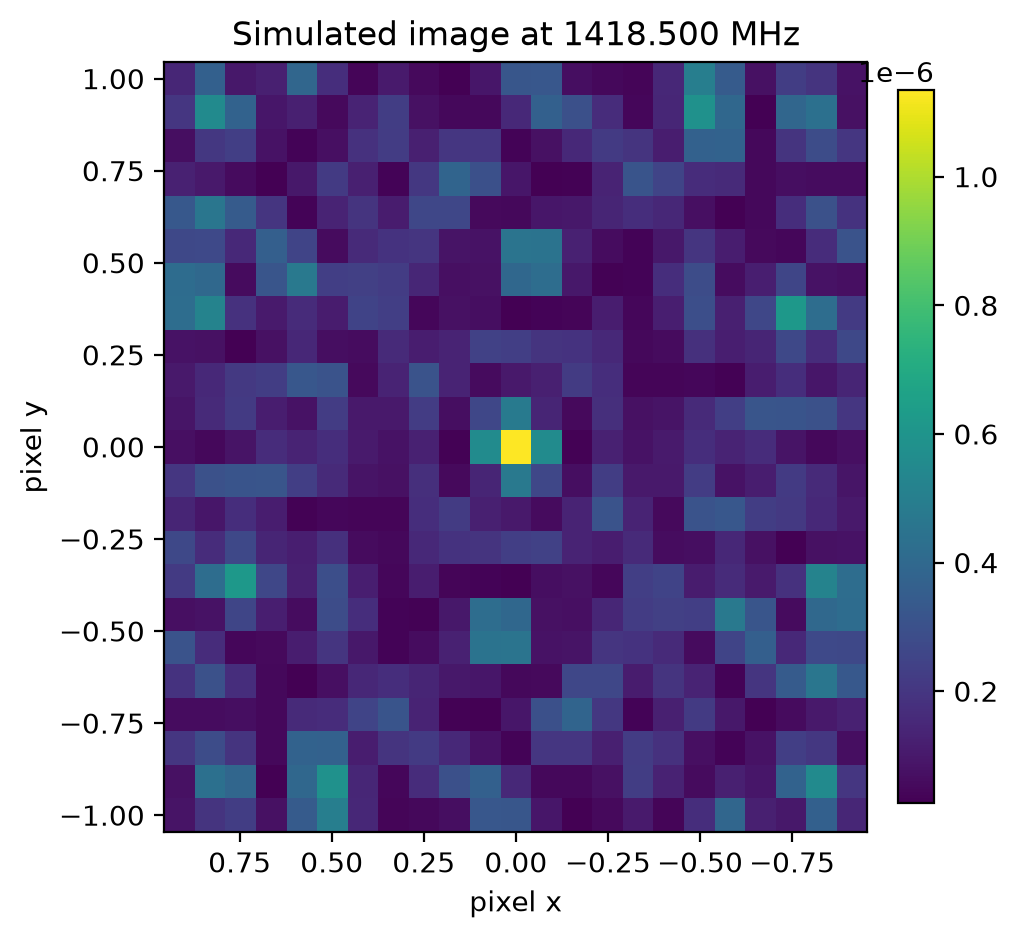

In [17]:
# Make and plot image

f = subband_frequency(subband)
fwhm =  ((c.c/f)/(largest_baseline)).decompose()*u.rad
sky_coverage = 2*u.rad
num_pix = int(sky_coverage / (fwhm/2.5))
print(f"Number of pixels should be {num_pix}")

obs_num = 0

#img, extent = make_image(acm[obs_num],num_pix,uv_blocks[obs_num],f)

img, extent = make_image(acm[obs_num, :, :], num_pix, uv[obs_num, :, :, :], f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(np.abs(img), origin='lower', extent=extent)

ax.set_title(f"Simulated image at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


### 3.3 Make image of the PSF

Output()

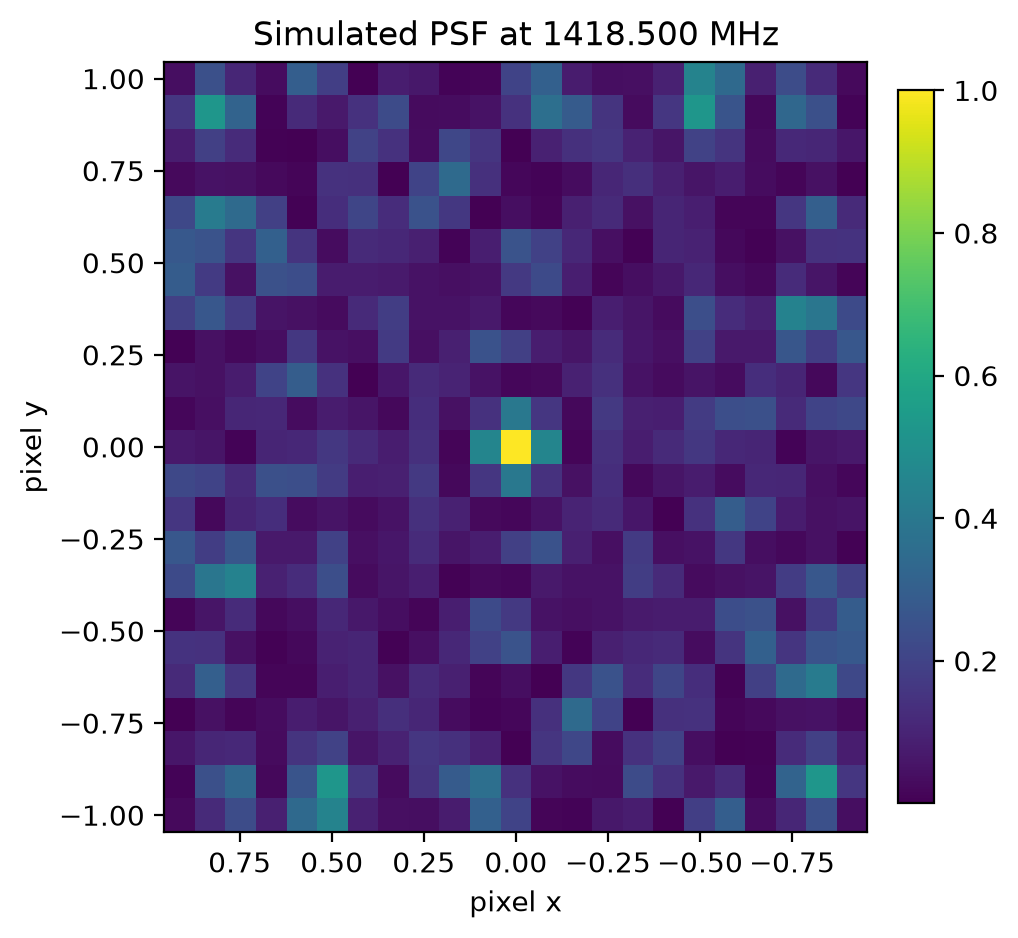

In [ ]:
psf, psf_extent = make_image(np.ones_like(acm[obs_num, :, :]), num_pix, uv[obs_num, :, :, :], f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im_psf = ax.imshow(psf, extent=psf_extent, origin='lower')

ax.set_title(f"Simulated PSF at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im_psf, ax=ax, fraction=0.046, pad=0.04)
plt.show()

# 4 Perform clean algorithm on simulated data

In [19]:
def hdfig(subplots_def=None, scale=0.5, figsize=(8, 4.5)):
    """ Returns figure according to the LOFAR notebook"""
    fig = plt.figure(figsize=figsize, dpi=scale*1920/8)
    if subplots_def is None:
        return fig
    else:
        return fig, fig.subplots(*subplots_def)
    
def gaussian(height, center_x, center_y, width_x, width_y):
    """Returns a gaussian function with the given parameters"""
    width_x = float(width_x)
    width_y = float(width_y)
    return lambda x,y: height*np.exp(
                -(((center_x-x)/width_x)**2+((center_y-y)/width_y)**2)/2)

def moments(data):
    """Returns (height, x, y, width_x, width_y)
    the gaussian parameters of a 2D distribution by calculating its
    moments """
    total = data.sum()
    X, Y = np.indices(data.shape)
    x = (X*data).sum()/total
    y = (Y*data).sum()/total
    col = data[:, int(y)]
    width_x = np.sqrt(np.abs((np.arange(col.size)-x)**2*col).sum()/col.sum())
    row = data[int(x), :]
    width_y = np.sqrt(np.abs((np.arange(row.size)-y)**2*row).sum()/row.sum())
    height = data.max()
    return height, x, y, width_x, width_y

def fitgaussian(data):
    """Returns (height, x, y, width_x, width_y)
    the gaussian parameters of a 2D distribution found by a fit"""
    params = moments(data)
    errorfunction = lambda p: np.ravel(gaussian(*p)(*np.indices(data.shape)) -
                                 data)
    p, success = scipy.optimize.leastsq(errorfunction, params)
    return p

def subtraction(img_I, psf, gamma, model_image, max_strength_allowed, start_progress, num_pix):
    """Returns the image with subtracted psf, the new maxiumum value and the input model image with the found brightest point subtracted"""
# function to subract the psf centred around the brightest point in the image

    max_strength = max(img_I.reshape(num_pix**2)) # determine value of brightest pixel
    max_pos = np.where(img_I==max_strength)
    model_image[max_pos[0], max_pos[1]] += max_strength # add pixel brightness to model image

    percentage = (max_strength_allowed-max_strength)/start_progress # progress attempt
    if percentage*100 % 10 == 0:
        print(f"{percentage:.0%}")


    psf_sub = psf * max_strength * gamma # multiply dirty beam with max strength and gamma factor
    shift_psf = ndimage.shift(psf_sub, (-((num_pix//2)-max_pos[0]), -((num_pix//2)-max_pos[1]))) # shift psf centre to brightest pixel

    new_image = img_I-shift_psf # remove psf from image
    
    max_strength = max(new_image.reshape(num_pix**2)) # calculate new maximum
    return {
        "new_pic" : new_image,
        "max_value" : max_strength,
        "model_image" : model_image,

    }


### 4.1 Loop over image until max pixel value is reached

In [20]:
max_strength = max(img.reshape(num_pix**2)) # starting maximum value of the image
max_allowed = 0.5*1e-7 # set this to the maximum you want the cleaner to go to 
new_image = img.copy()
model_image = np.zeros_like(img)
start = max_allowed-max_strength

gamma = 0.5 # set this to the needed gamma parameter for cleaning

while max_strength>max_allowed: # cleaning loop runs until the brightest point in the image is less bright than the set max_allowed
    info = subtraction(new_image, psf, gamma, model_image, max_allowed, start, num_pix)
    new_image = info["new_pic"] 
    max_strength = info["max_value"]
    model_image = info["model_image"]

100%


### 4.2 Convolve the image

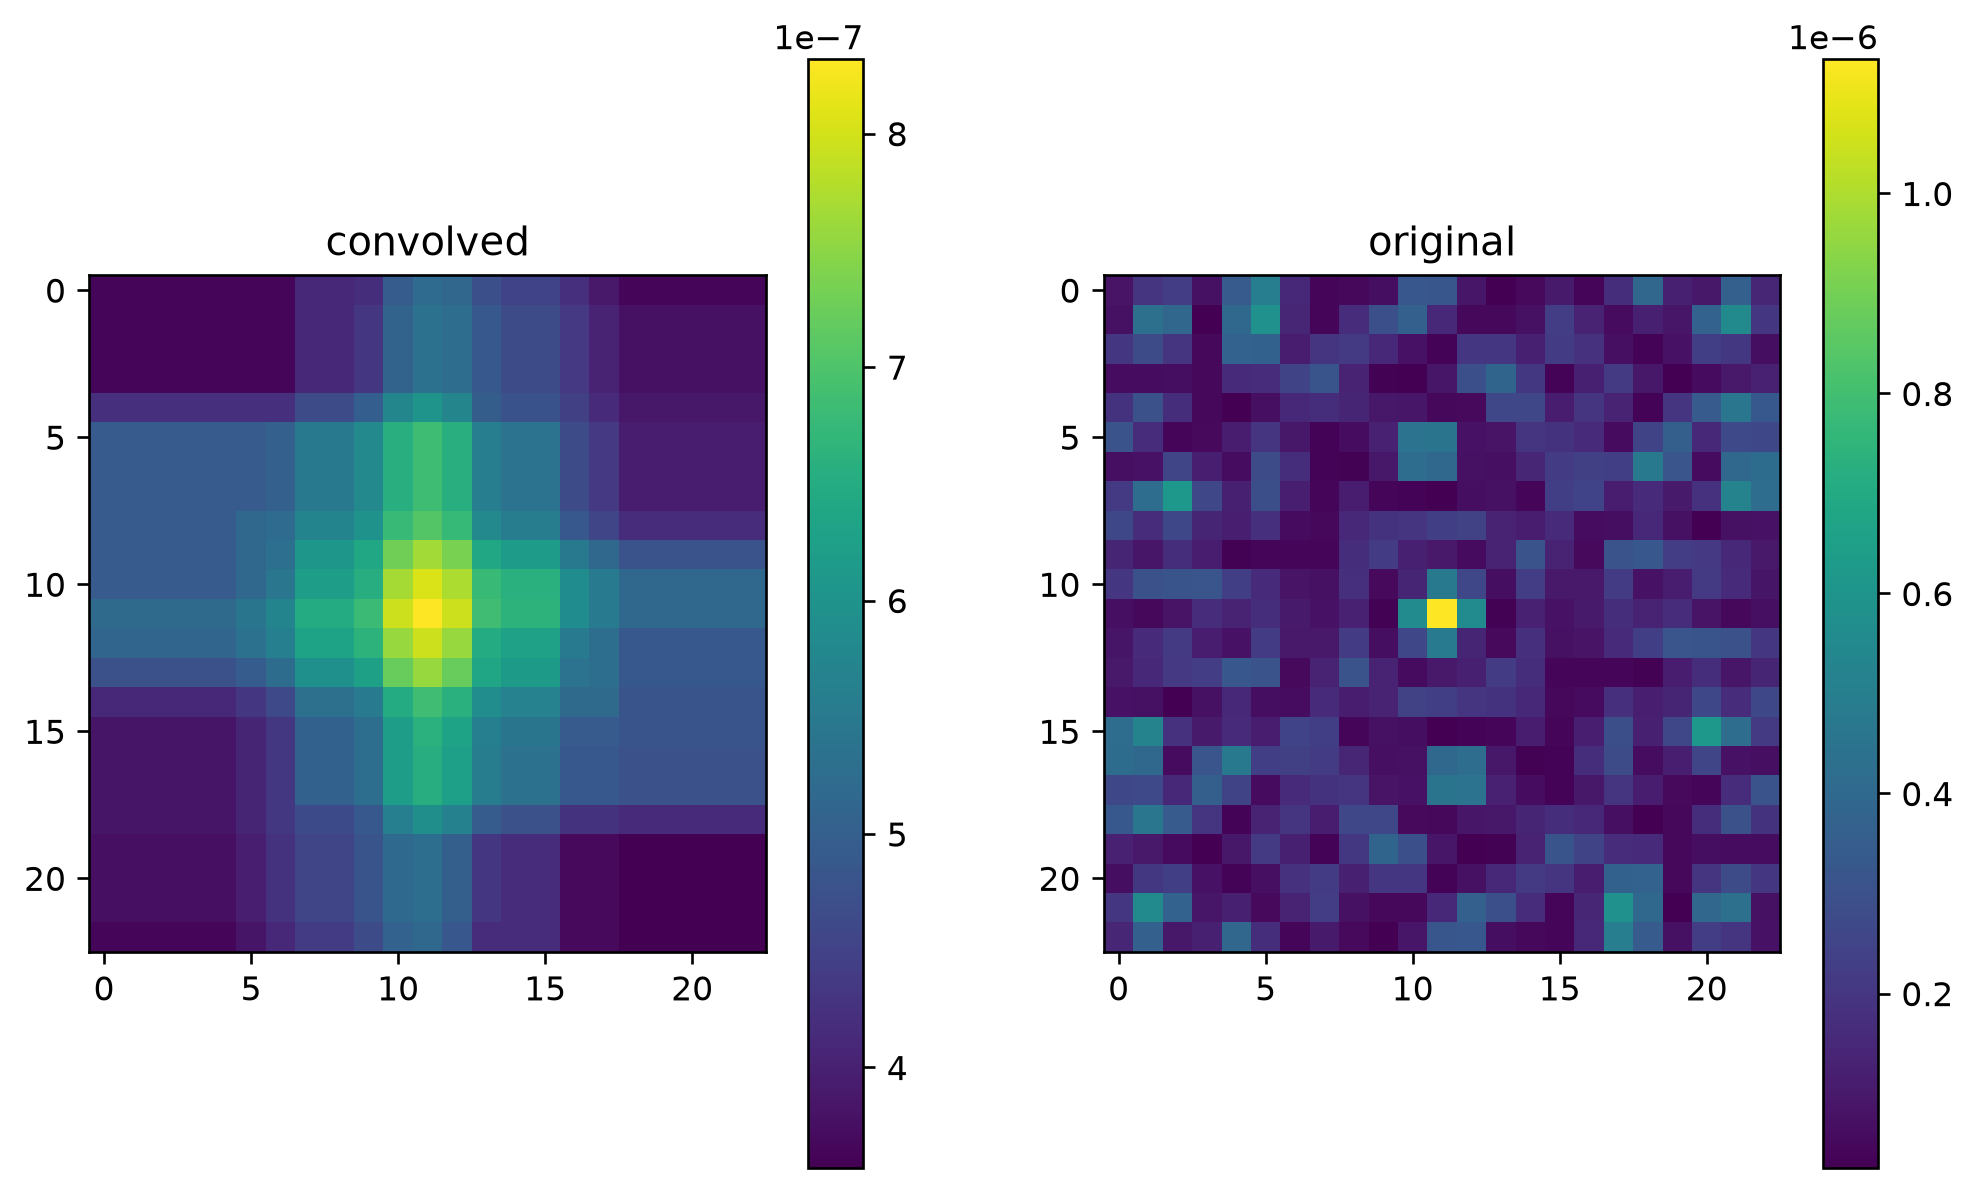

In [21]:
params = fitgaussian(psf)
fit = gaussian(*params)
clean_beam = fit(*np.indices(psf.shape))

convolved_image = scipy.signal.fftconvolve(model_image, clean_beam, mode = "same")

fig, (ax_xx, ax_yy) = hdfig((1,2), figsize=(10,6))
mp_xx = ax_xx.imshow(convolved_image)
ax_xx.set_title("convolved")
mp_yy = ax_yy.imshow(img)
ax_yy.set_title("original")

fig.colorbar(mp_xx, ax=ax_xx)
fig.colorbar(mp_yy, ax=ax_yy)

# 5 Simulate time delays

In [22]:
def add_delay_errors(acm, frequency, delay_rms_ns, seed=None):
    freq = frequency.to(u.Hz)
    
    n_ant = acm.shape[0]

    # Independent delay error for each antenna (seconds)
    delays = np.random.normal(0, delay_rms_ns *1e-9, n_ant)

    # Delay difference for each antenna pair
    delay_matrix = delays[None, :] - delays[:, None]

    # Convert delay errors to phase errors
    phase_errors = 2 * np.pi * freq * delay_matrix

    # Apply phase errors to the visibility matrix
    acm_corrupted = acm * np.exp(1j * phase_errors.value)

    return acm_corrupted, delays

### 5.1 Visualise time delays

Output()

Output()

Output()

Output()

Output()

Output()

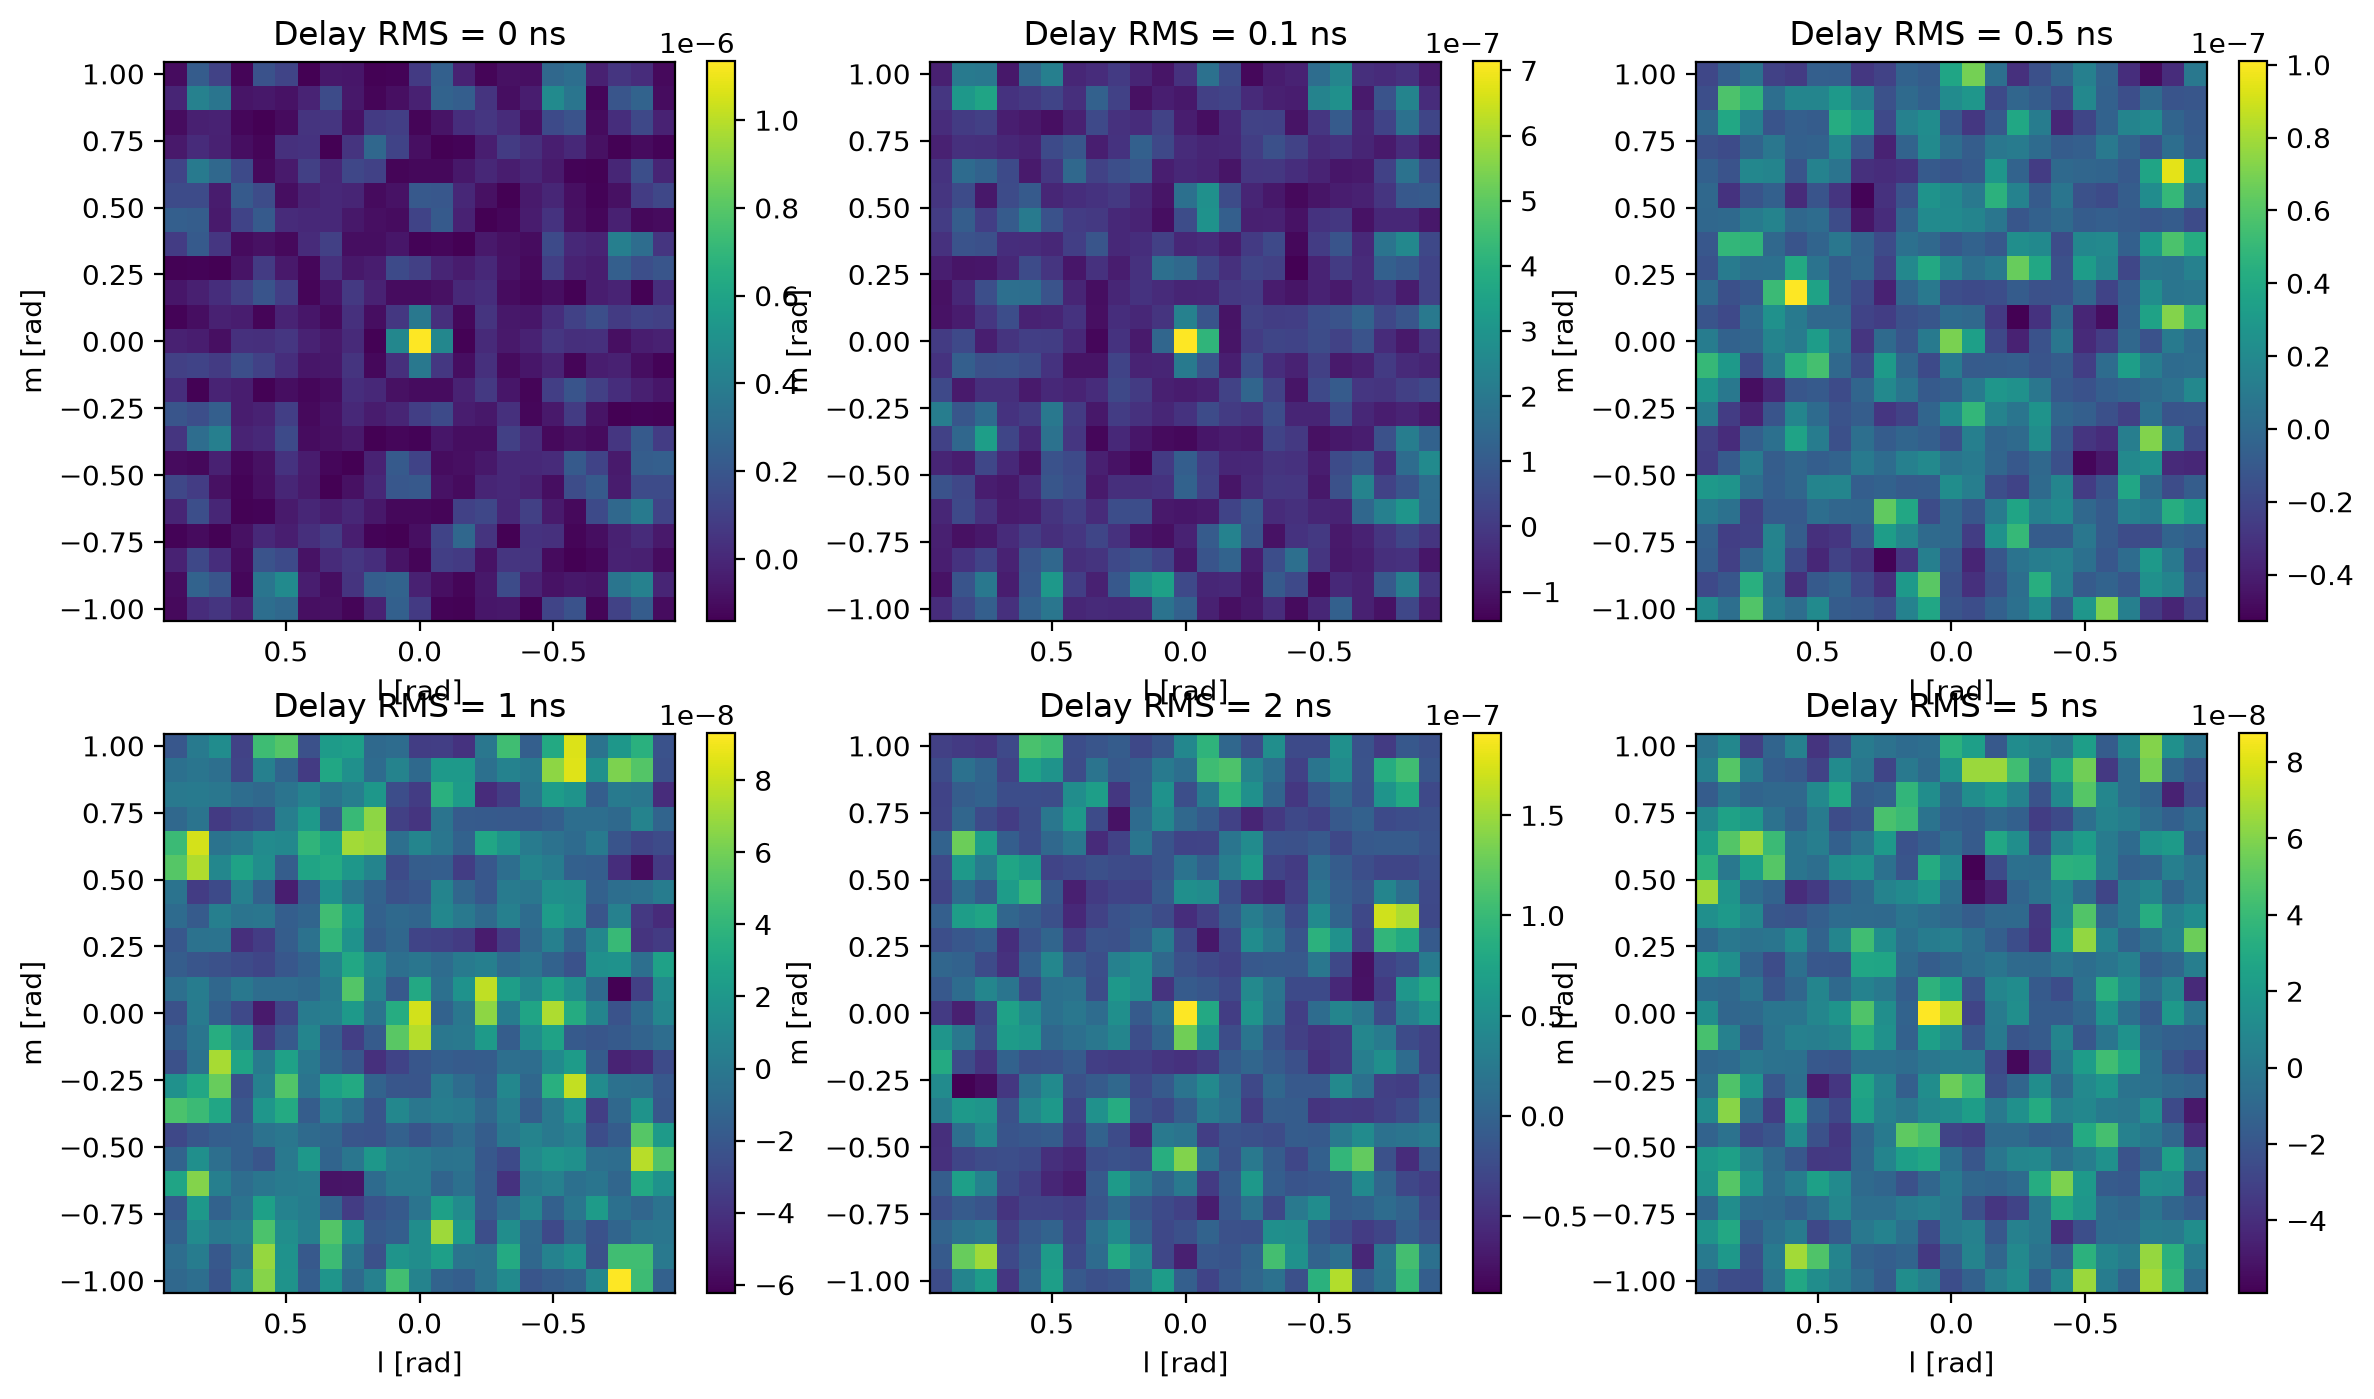

In [23]:
delay_errors = [0, 0.1, 0.5, 1, 2, 5]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, delay_ns in zip(axes.flat, delay_errors):

    acm_test, delays = add_delay_errors(acm[0], f, delay_ns)

    img, extent = make_image(acm_test, num_pix, uv, f)

    im = ax.imshow(img, origin="lower", extent=extent)

    ax.set_title(f"Delay RMS = {delay_ns} ns")
    ax.set_xlabel("l [rad]")
    ax.set_ylabel("m [rad]")

    fig.colorbar(im, ax=ax)

plt.show()
